# Biome shifts


Set path to include RStudio packages.

In [1]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

## Load Data

### Summary stats per hexagon

In [2]:
# Load all packages used in this notebook
library(data.table)
library(dplyr)
library(tidyr)
library(tibble)
library(sf)
library(h3)
library(ggplot2)
library(effsize)  # Cliff's Delta

dtn = 10
setDTthreads(threads = dtn) # defines how many threads data.table is allowed to use


Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Linking to GEOS 3.12.1, GDAL 3.8.4, PROJ 9.4.0; sf_use_s2() is TRUE



In [3]:
combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree_group.csv")
head(combined_data)



h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,⋯,X.X237,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83001afffffffff,all,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,-0.016,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152
83001afffffffff,native,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,-0.016,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152
83001cfffffffff,all,-10.005360,-0.2380058,0.2491376,2.9137390,0.9757523,1,1,16.22,⋯,-0.119,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3166111,0.175
83001cfffffffff,native,-9.988809,-0.3014320,0.2822225,2.9136399,0.9666302,1,1,16.22,⋯,-0.119,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3291221,0.175
83001efffffffff,all,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,0.122,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211
83001efffffffff,native,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,0.122,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211


In [4]:
dim(combined_data)

[1] 19504    47

In [5]:
summary(combined_data$X.X47)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  0.070   0.257   0.284   0.293   0.318   0.656 

In [6]:
summary_data <- fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree.csv")
head(summary_data)

h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC5_all,⋯,X.X47..mean_native,X.X47..median_all,X.X47..median_native,X.X47..percent_change_mean,X.X47..percent_change_median,X.X47..n_na_all,X.X47..perc_na_all,X.X47..n_na_native,X.X47..perc_na_native,resolution
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<int>,<dbl>,<chr>
83831efffffffff,4.791148,3.7766291,0.9721051,1.1088903,-0.5431612,-0.34431243,-0.42136533,1.02068041,0.5774828,⋯,0.322,0.352,0.354,0.00,-0.56,37,24.67,16,19.05,h3_res3
838218fffffffff,3.901431,5.0583305,1.1307036,0.5138983,-0.2462778,0.05720839,-0.47252956,-0.54789381,0.2955384,⋯,0.293,0.276,0.285,-6.83,-3.16,10,26.32,10,34.48,h3_res3
838233fffffffff,5.296893,7.9646210,0.7344789,0.1759947,-0.3730047,0.69734595,-1.40549703,-1.56500099,1.3152798,⋯,0.290,0.324,0.280,3.79,15.71,8,26.67,7,43.75,h3_res3
838230fffffffff,5.160745,6.4376781,1.1521587,0.7619902,-0.9373319,-0.01892562,0.09261112,0.81461843,0.8814747,⋯,0.308,0.305,0.315,-1.30,-3.17,11,31.43,8,40.00,h3_res3
83be4dfffffffff,0.601728,0.6843753,-7.7335394,-7.9253400,2.7755032,2.86621941,0.47608132,0.46676308,-0.6878360,⋯,0.496,0.497,0.514,-1.21,-3.31,7924,25.99,7837,26.22,h3_res3
835f12fffffffff,3.826443,4.0358059,0.6390104,0.5204550,0.7138565,0.88520839,0.10669870,0.06196723,0.1184253,⋯,0.303,0.305,0.307,-0.33,-0.65,2374,21.61,2095,22.12,h3_res3


### Olsen polygons

#### Preprocessing

Create new region code by combining Biome x Realm.

*This section only needs to run once; it writes the aggregated shapefile that is read in the next section. You can skip it if `wwf_terr_ecos_aggregated.shp` already exists.*

In [ ]:
library(sf) 

wwf <- st_read("~/iNaturalist/Data/WWF/wwf_terr_ecos.shp")
# Remove arctic and Antarctica
#wwf <- wwf[wwf$BIOME < 98, ]


In [ ]:
print(wwf) # check the structure of the shapefile

In [ ]:
plot(wwf["BIOME"]) 

In [ ]:
wwf$biome_realm <- paste(wwf$BIOME, wwf$REALM, sep = "_")

In [ ]:
# Ensure all geometries are valid
wwf <- st_make_valid(wwf)

In [ ]:
# Aggregate polygons by BIOME and REALM
wwf_aggregated <- wwf %>%
    group_by(biome_realm) %>%
    summarise(geometry = st_union(geometry))

# Check the structure of the aggregated data
print(wwf_aggregated)

In [ ]:
# save the aggregated shapefile
st_write(wwf_aggregated, "~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp", delete_dsn = TRUE)

#### Load data

In [7]:
# read the aggregated shapefile
library(sf)
wwf_aggregated <- st_read("~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp")


Reading layer `wwf_terr_ecos_aggregated' from data source 
  `/net/home/swolf/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 64 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84


In [8]:
print(wwf_aggregated)

Simple feature collection with 64 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
First 10 features:
   bim_rlm                       geometry
1    10_AA MULTIPOLYGON (((171.4289 -4...
2    10_AT MULTIPOLYGON (((34.56465 1....
3    10_IM MULTIPOLYGON (((116.6342 6....
4    10_NT MULTIPOLYGON (((-76.14241 4...
5    10_PA MULTIPOLYGON (((64.75403 34...
6    11_AA MULTIPOLYGON (((179.1841 -4...
7    11_AN MULTIPOLYGON (((-66.89195 -...
8    11_NA MULTIPOLYGON (((-42.17305 6...
9    11_PA MULTIPOLYGON (((149.4331 68...
10   12_AA MULTIPOLYGON (((122.7533 -3...


Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”


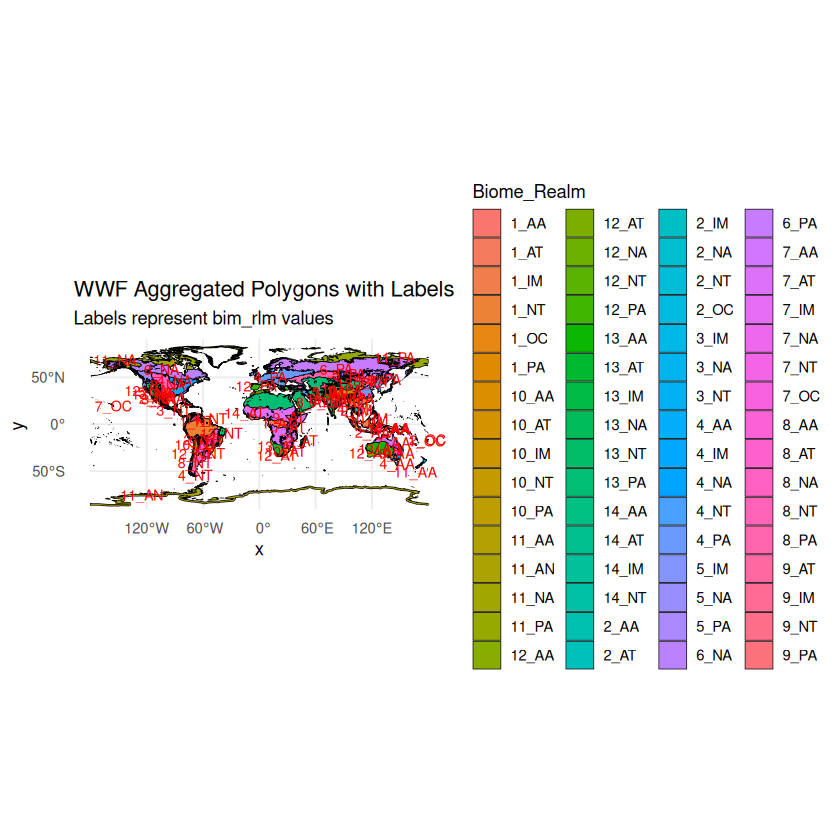

In [9]:
library(ggplot2)

# Plot the aggregated WWF data with labels and different colors for each polygon
ggplot() +
    geom_sf(data = wwf_aggregated, aes(fill = bim_rlm), color = "black") +
    geom_sf_text(data = wwf_aggregated, aes(label = bim_rlm), size = 3, color = "red") +
    theme_minimal() +
    labs(title = "WWF Aggregated Polygons with Labels",
         subtitle = "Labels represent bim_rlm values",
         fill = "Biome_Realm")

In [10]:
wwf_aggregated_h3 <- wwf_aggregated %>%
  rowwise() %>%
  mutate(
    h3_indexes = {
      pf <- h3::polyfill(geometry, res = 3)
      if (length(pf) == 0) { # small polygons where the no h3_hexagon centroid fall within the polygon
        # Fallback: use centroid
        centroid <- sf::st_centroid(geometry)
        coords <- sf::st_coordinates(centroid)
        pf <- h3::geo_to_h3(matrix(coords[c(2,1)], nrow=1), res = 3)  # lat, lon order
      }
      list(pf)
    },
    
    # Expand one ring as before
    h3_indexes_k1 = list({
      base <- h3_indexes
      expanded <- unique(unlist(lapply(base, function(ix) h3::k_ring(ix))))
      expanded
    }),
    
    h3_outer_ring = list(setdiff(h3_indexes_k1, h3_indexes))
  ) %>%
  ungroup()

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has 

In [11]:
print(wwf_aggregated_h3)

Simple feature collection with 64 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
# A tibble: 64 × 5
   bim_rlm                       geometry h3_indexes h3_indexes_k1 h3_outer_ring
   <chr>               <MULTIPOLYGON [°]> <list>     <list>        <list>       
 1 10_AA   (((171.4289 -43.18564, 171.42… <chr [7]>  <chr [44]>    <chr [37]>   
 2 10_AT   (((34.56465 1.082489, 34.5001… <chr [64]> <chr [175]>   <chr [111]>  
 3 10_IM   (((116.6342 6.288008, 116.646… <chr [1]>  <chr [7]>     <chr [6]>    
 4 10_NT   (((-76.14241 4.993758, -76.12… <chr [66]> <chr [148]>   <chr [82]>   
 5 10_PA   (((64.75403 34.78774, 64.7537… <chr>      <chr [519]>   <chr [257]>  
 6 11_AA   (((179.1841 -47.72759, 179.17… <chr [1]>  <chr [7]>     <chr [6]>    
 7 11_AN   (((-66.89195 -67.89795, -66.9… <chr>      <chr [589]>   <chr [348]>  
 8 11_NA   (((-42.17305 62.48101, -42.18… <chr>      <chr [73

## Add BIOME and REALM code

In [12]:
# Start from a clean region column so the assignment below is reproducible
combined_data$region <- NA_character_

In [13]:
# Load necessary libraries
library(sf)
library(h3)
library(dplyr)

# Step 1: Iterate over all regions in the wwf dataset
for (region in unique(wwf_aggregated$bim_rlm)) {
  # Extract the polygon for the current region
  polygon <- wwf_aggregated[wwf_aggregated$bim_rlm == region, ]
  
  # Convert the polygon to H3 cells (Resolution 3)
  region_cells <- h3::polyfill(polygon, res = 3)
  
  # Assign the region name to the corresponding cells in combined_data
  combined_data$region[combined_data$h3_res3 %in% region_cells] <- region
}

# Step 2: View the updated combined_data
head(combined_data)

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has 

h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,⋯,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47,region
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
83001afffffffff,all,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152,11_PA
83001afffffffff,native,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152,11_PA
83001cfffffffff,all,-10.005360,-0.2380058,0.2491376,2.9137390,0.9757523,1,1,16.22,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3166111,0.175,NA
83001cfffffffff,native,-9.988809,-0.3014320,0.2822225,2.9136399,0.9666302,1,1,16.22,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3291221,0.175,NA
83001efffffffff,all,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211,NA
83001efffffffff,native,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211,NA


In [14]:
table(is.na(combined_data$region))


FALSE  TRUE 
16150  3354 

In [15]:
# number of rows without a region assigned
sum(is.na(combined_data$region))

[1] 3354

In [16]:
# Assign original H3 cells + one outer ring to cells that are still NA

for (i in seq_len(nrow(wwf_aggregated_h3))) {
  
  region <- wwf_aggregated_h3$bim_rlm[i]
  
  region_cells <- wwf_aggregated_h3$h3_indexes_k1[[i]]
  
  combined_data$region[
    is.na(combined_data$region) &
    combined_data$h3_res3 %in% region_cells
  ] <- region
}

In [17]:
sum(is.na(combined_data$region))

[1] 498

In [18]:
table(is.na(combined_data$region))


FALSE  TRUE 
19006   498 

In [19]:
# remove duplicate rows based on h3_res3 and group, keeping the first occurrence
combined_data <- combined_data %>%
  group_by(h3_res3, group) %>%
  slice(1) %>%
  ungroup()

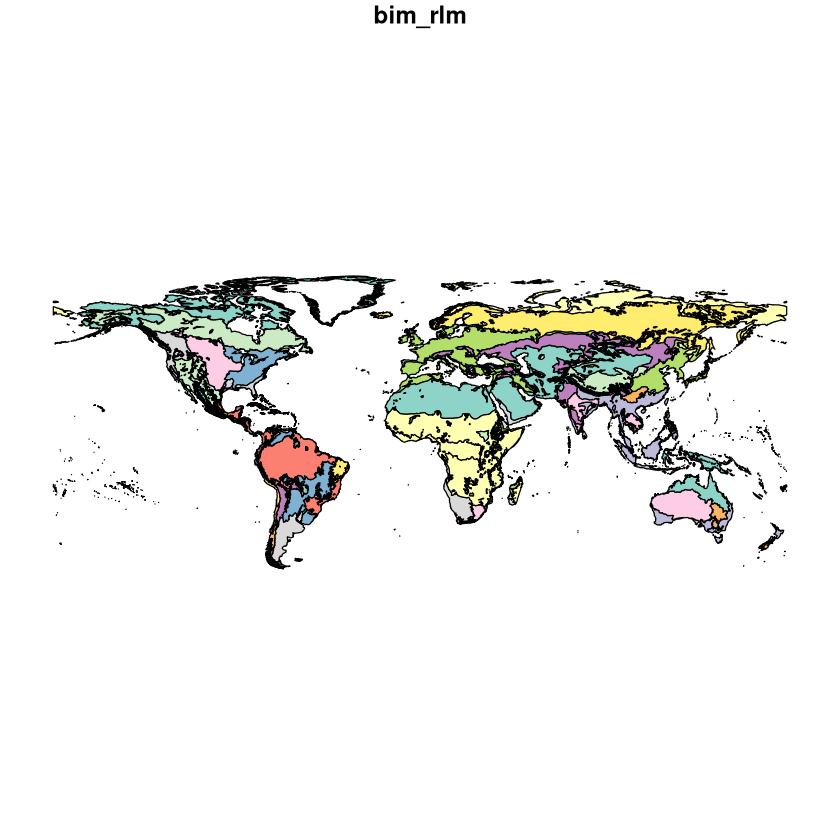

In [20]:
# Filter wwf_aggregated for bim_rlm values in unique(combined_data$region)
filtered_wwf_aggregated <- wwf_aggregated %>%
    filter(bim_rlm %in% unique(combined_data$region))

# Plot the filtered data
plot(filtered_wwf_aggregated["bim_rlm"])

In [21]:
table(is.na(combined_data$region))


FALSE  TRUE 
19006   498 

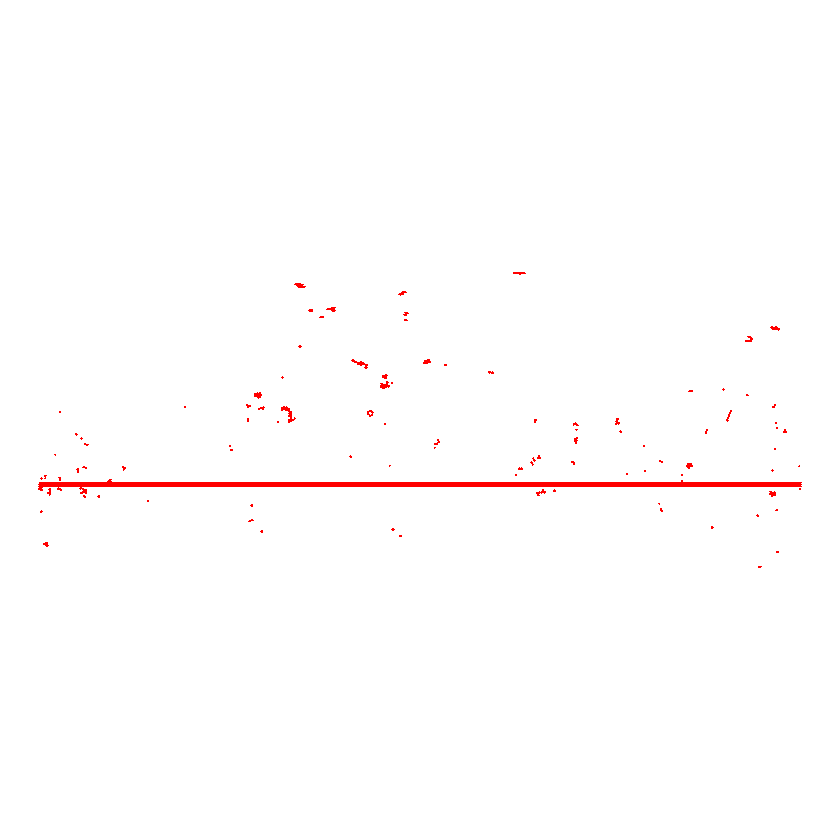

In [22]:
library(sf)
library(dplyr)
library(h3)
library(ggplot2)

na_cells <- combined_data %>%
  filter(is.na(region)) %>%
  pull(h3_res3)

na_polygons <- lapply(na_cells, function(h) {
  
  coords <- h3_to_geo_boundary(h)
  
  # Convert list of lon/lat pairs to matrix
  coords <- do.call(rbind, coords)
  
  # H3 returns lat, lon -> sf needs lon, lat
  coords <- coords[, c(2, 1)]
  
  # Close polygon
  coords <- rbind(coords, coords[1, ])
  
  st_polygon(list(coords))
})

na_sf <- st_sf(
  h3_res3 = na_cells,
  geometry = st_sfc(na_polygons, crs = 4326)
)

ggplot() +
  geom_sf(
    data = na_sf,
    fill = "red",
    color = NA
  ) +
  theme_void()

Costal regions successfully added - only islands not added to biomes

In [23]:
# unique h3_res3 values
length(unique(combined_data$h3_res3))

[1] 9752

In [24]:
# save combined_data with region info
#fwrite(combined_data, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10.csv") ## PREPRINT VERSION
#fwrite(combined_data, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10_notrim_LCweighted.csv")
fwrite(combined_data, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10_notrim_misstree.csv")


In [25]:
head(combined_data)

h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,⋯,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47,region
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
83001afffffffff,all,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152,11_PA
83001afffffffff,native,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152,11_PA
83001cfffffffff,all,-10.005360,-0.2380058,0.2491376,2.9137390,0.9757523,1,1,16.22,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3166111,0.175,NA
83001cfffffffff,native,-9.988809,-0.3014320,0.2822225,2.9136399,0.9666302,1,1,16.22,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3291221,0.175,NA
83001efffffffff,all,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211,11_PA
83001efffffffff,native,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211,11_PA


## Significance tests for shifts along PCA axes per region


### Unpaired Wilcoxon Rank Sum Test

In [26]:
# read "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10_notrim_misstree.csv")
combined_data <- read.csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10_notrim_misstree.csv")

In [27]:
head(combined_data)

,h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,⋯,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47,region
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,83001afffffffff,all,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152,11_PA
2,83001afffffffff,native,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152,11_PA
3,83001cfffffffff,all,-10.005360,-0.2380058,0.2491376,2.9137390,0.9757523,1,1,16.22,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3166111,0.175,
4,83001cfffffffff,native,-9.988809,-0.3014320,0.2822225,2.9136399,0.9666302,1,1,16.22,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3291221,0.175,
5,83001efffffffff,all,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211,11_PA
6,83001efffffffff,native,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211,11_PA


In [28]:
unpaired_wilcoxon_results <- combined_data %>%
    group_by(region) %>%
    summarise(
        wilcox_p_value_PC1 = wilcox.test(PC1[group == "all"], PC1[group == "native"], paired = FALSE)$p.value,
        wilcox_p_value_PC2 = wilcox.test(PC2[group == "all"], PC2[group == "native"], paired = FALSE)$p.value,
        wilcox_p_value_PC3 = wilcox.test(PC3[group == "all"], PC3[group == "native"], paired = FALSE)$p.value,
        wilcox_p_value_PC4 = wilcox.test(PC4[group == "all"], PC4[group == "native"], paired = FALSE)$p.value,
        wilcox_p_value_PC5 = wilcox.test(PC5[group == "all"], PC5[group == "native"], paired = FALSE)$p.value
    )

Warning message:
“There were 55 warnings in `summarise()`.
The first warning was:
ℹ In argument: `wilcox_p_value_PC1 = wilcox.test(PC1[group == "all"], PC1[group
  == "native"], paired = FALSE)$p.value`.
ℹ In group 22: `region = "14_AT"`.
Caused by warning in `wilcox.test.default()`:
! cannot compute exact p-value with ties
ℹ Run `dplyr::last_dplyr_warnings()` to see the 54 remaining warnings.”


In [29]:
# adjust for multiple testing using Benjamini-Hochberg method

unpaired_wilcoxon_results <- unpaired_wilcoxon_results %>%
    mutate(
        adjusted_p_value_PC1 = p.adjust(wilcox_p_value_PC1, method = "BH"),
        adjusted_p_value_PC2 = p.adjust(wilcox_p_value_PC2, method = "BH"),
        adjusted_p_value_PC3 = p.adjust(wilcox_p_value_PC3, method = "BH"),
        adjusted_p_value_PC4 = p.adjust(wilcox_p_value_PC4, method = "BH"),
        adjusted_p_value_PC5 = p.adjust(wilcox_p_value_PC5, method = "BH")  
    )

In [30]:
# Filter for adjusted p-values < 0.05
unpaired_wilcox_significant <- unpaired_wilcoxon_results %>%
    filter(adjusted_p_value_PC1 < 0.05 | adjusted_p_value_PC2 < 0.05 | adjusted_p_value_PC3 < 0.05 | adjusted_p_value_PC4 < 0.05 | adjusted_p_value_PC5 < 0.05) %>%
    mutate(
        significance_PC1 = case_when(
            adjusted_p_value_PC1 < 0.001 ~ "***",
            adjusted_p_value_PC1 < 0.01 ~ "**",
            adjusted_p_value_PC1 < 0.05 ~ "*",
            TRUE ~ ""
        ),
        significance_PC2 = case_when(
            adjusted_p_value_PC2 < 0.001 ~ "***",
            adjusted_p_value_PC2 < 0.01 ~ "**",
            adjusted_p_value_PC2 < 0.05 ~ "*",
            TRUE ~ ""
        ),
        significance_PC3 = case_when(
            adjusted_p_value_PC3 < 0.001 ~ "***",
            adjusted_p_value_PC3 < 0.01 ~ "**",
            adjusted_p_value_PC3 < 0.05 ~ "*",
            TRUE ~ ""
        ),
        significance_PC4 = case_when(
            adjusted_p_value_PC4 < 0.001 ~ "***",
            adjusted_p_value_PC4 < 0.01 ~ "**",
            adjusted_p_value_PC4 < 0.05 ~ "*",
            TRUE ~ ""
        ),
        significance_PC5 = case_when(
            adjusted_p_value_PC5 < 0.001 ~ "***",
            adjusted_p_value_PC5 < 0.01 ~ "**",
            adjusted_p_value_PC5 < 0.05 ~ "*",
            TRUE ~ ""
        )
    )

unpaired_wilcox_significant

region,wilcox_p_value_PC1,wilcox_p_value_PC2,wilcox_p_value_PC3,wilcox_p_value_PC4,wilcox_p_value_PC5,adjusted_p_value_PC1,adjusted_p_value_PC2,adjusted_p_value_PC3,adjusted_p_value_PC4,adjusted_p_value_PC5,significance_PC1,significance_PC2,significance_PC3,significance_PC4,significance_PC5
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
10_AT,8.719658e-01,4.207698e-03,2.203317e-04,0.0900258621,3.366266e-01,1.000000e+00,0.0226065532,1.982985e-03,0.533928357,0.9457627119,,*,**,,
12_AA,2.259178e-01,2.157612e-03,4.286385e-01,0.5385143619,5.921100e-01,7.643427e-01,0.0151032852,6.137325e-01,1.000000000,0.9457627119,,*,,,
12_NA,8.468599e-02,5.176616e-03,5.914718e-02,0.0371140333,3.717066e-01,5.335217e-01,0.0250866762,1.552613e-01,0.323863636,0.9457627119,,*,,,
12_PA,1.986729e-09,2.584417e-02,8.925544e-01,0.0050198386,6.925682e-01,6.258197e-08,0.0740083125,9.767833e-01,0.115243236,0.9457627119,***,,,,
13_IM,8.940017e-01,4.256196e-04,2.901169e-02,0.1043814459,8.953598e-02,1.000000e+00,0.0038305765,1.015409e-01,0.533928357,0.9457627119,,**,,,
13_NT,5.643664e-01,9.752796e-03,4.289587e-02,0.2230978672,8.618282e-01,9.609482e-01,0.0384016332,1.351220e-01,0.826774449,0.9457627119,,*,,,
1_IM,3.450647e-10,2.356993e-04,8.347295e-13,0.0084222834,6.170912e-01,2.173907e-08,0.0029698108,2.629398e-11,0.115243236,0.9457627119,***,**,***,,
1_NT,5.130765e-01,1.787035e-04,6.006071e-05,0.5837777015,1.752028e-01,9.155777e-01,0.0028145800,6.898352e-04,1.000000000,0.9457627119,,**,***,,
2_AA,2.426485e-01,8.469987e-01,1.576906e-02,0.0000538677,7.969358e-01,7.643427e-01,1.0000000000,6.209068e-02,0.003393665,0.9457627119,,,,**,


In [31]:
print(unpaired_wilcox_significant$region)

 [1] "10_AT" "12_AA" "12_NA" "12_PA" "13_IM" "13_NT" "1_IM"  "1_NT"  "2_AA" 
[10] "2_IM"  "2_NT"  "2_OC"  "4_AA"  "4_NA"  "4_NT"  "4_PA"  "5_NA"  "6_NA" 
[19] "7_AA"  "7_AT"  "7_NT"  "8_NA"  "8_NT" 


### Global shift statistics

In [32]:
unpaired_wilcoxon_results_global <- combined_data %>%
    summarise(
        wilcox_p_value_PC1 = wilcox.test(PC1[group == "all"], PC1[group == "native"], paired = FALSE)$p.value,
        wilcox_p_value_PC2 = wilcox.test(PC2[group == "all"], PC2[group == "native"], paired = FALSE)$p.value,
        wilcox_p_value_PC3 = wilcox.test(PC3[group == "all"], PC3[group == "native"], paired = FALSE)$p.value,
        wilcox_p_value_PC4 = wilcox.test(PC4[group == "all"], PC4[group == "native"], paired = FALSE)$p.value,
        wilcox_p_value_PC5 = wilcox.test(PC5[group == "all"], PC5[group == "native"], paired = FALSE)$p.value
    )
unpaired_wilcoxon_results_global

wilcox_p_value_PC1,wilcox_p_value_PC2,wilcox_p_value_PC3,wilcox_p_value_PC4,wilcox_p_value_PC5
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.8521155,8.014769e-15,1.01888e-23,0.0002671337,0.2284107


## Filter for regions with significant shifts



In [33]:
unpaired_wilcox_significant$region

[1] "10_AT" "12_AA" "12_NA" "12_PA" "13_IM" "13_NT" "1_IM"  "1_NT"  "2_AA" 
[10] "2_IM"  "2_NT"  "2_OC"  "4_AA"  "4_NA"  "4_NT"  "4_PA"  "5_NA"  "6_NA" 
[19] "7_AA"  "7_AT"  "7_NT"  "8_NA"  "8_NT"

In [34]:
combined_data_filtered <- combined_data %>%
    filter(region %in% unpaired_wilcox_significant$region)
head(combined_data_filtered)

,h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,⋯,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47,region
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,830880fffffffff,all,-2.349345,2.536676,0.5863514,-0.7775635,-0.1830555,6470,636,2.26,⋯,3.607,0.065,-0.522,87.804,2.505,3.441,-0.807,0.411,0.243,4_PA
2,830880fffffffff,native,-2.567193,2.360264,0.6696463,-0.8499218,-0.1908969,5423,468,1.50,⋯,3.610,0.062,-0.539,87.911,2.512,3.448,-0.712,0.411,0.249,4_PA
3,830882fffffffff,all,-2.427599,2.075851,0.6901786,-0.8732073,-0.3483760,5098,495,2.11,⋯,3.570,0.072,-0.518,88.592,2.560,3.411,-0.901,0.423,0.255,4_PA
4,830882fffffffff,native,-2.657638,1.894541,0.7466264,-0.9054329,-0.3084042,4291,362,1.44,⋯,3.576,0.070,-0.540,88.598,2.558,3.421,-0.846,0.422,0.261,4_PA
5,830883fffffffff,all,-3.352035,2.287114,0.5321793,0.2409389,0.2731109,8973,673,1.59,⋯,3.636,0.054,-0.547,89.340,2.590,3.517,-0.316,0.385,0.248,4_PA
6,830883fffffffff,native,-3.374981,2.281805,0.5926025,0.2564604,0.3422187,8564,585,1.54,⋯,3.638,0.054,-0.555,89.385,2.572,3.520,-0.309,0.382,0.249,4_PA


In [35]:
print(filtered_wwf_aggregated)

Simple feature collection with 62 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -55.97751 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
First 10 features:
   bim_rlm                       geometry
1    10_AA MULTIPOLYGON (((171.4289 -4...
2    10_AT MULTIPOLYGON (((34.56465 1....
3    10_IM MULTIPOLYGON (((116.6342 6....
4    10_NT MULTIPOLYGON (((-76.14241 4...
5    10_PA MULTIPOLYGON (((64.75403 34...
6    11_AA MULTIPOLYGON (((179.1841 -4...
7    11_NA MULTIPOLYGON (((-42.17305 6...
8    11_PA MULTIPOLYGON (((149.4331 68...
9    12_AA MULTIPOLYGON (((122.7533 -3...
10   12_AT MULTIPOLYGON (((22.58883 -3...


### Quantifying effect size: Cliff's Delta

#### Choosing the Best Effect Size Metric

When comparing plant trait shifts across regions, the choice of effect size metric depends on the type of data and the research question:

- **Cohen's d**: Suitable for comparing the magnitude of differences between two groups when data is normally distributed.
- **Rank-Biserial Correlation**: Ideal for non-parametric tests like the Wilcoxon signed-rank test, as it measures the proportion of favorable differences.
- **Cliff's Delta**: Useful for ordinal data or when assessing the degree of overlap between two distributions.
- **r (Correlation Coefficient)**: Provides a standardized measure of effect size, calculated as \( r = \frac{Z}{\sqrt{N}} \), where \( Z \) is the test statistic and \( N \) is the sample size.

For plant trait shifts, **Rank-Biserial Correlation** or **Cliff's Delta** are often preferred due to their robustness to non-normal data and ability to handle ordinal or skewed distributions.

Note: In this case, Rank-Biserial-Correlation yields the same numbers.

In [36]:
library(dplyr)
library(effsize) # For Cliff's Delta

# Initialize an empty list to store results
cliffs_delta_results <- list()

# Loop over all unique regions in combined_data_filtered
for (current_region in unique(combined_data_filtered$region)) {
    # Filter data for the current region
    filtered_data <- combined_data_filtered %>%
        filter(region == current_region & !is.na(PC1) & !is.na(PC2) & !is.na(PC3) & group %in% c("all", "native"))
    
    # Skip if there is insufficient data for the test
    if (nrow(filtered_data) < 2) {
        next
    }
    
    # Calculate Cliff's Delta for PC1
    cliffs_delta_PC1 <- tryCatch(
        {
            effsize::cliff.delta(
                filtered_data$PC1[filtered_data$group == "all"],
                filtered_data$PC1[filtered_data$group == "native"]
            )$estimate
        },
        error = function(e) NA
    )
    
    # Calculate Cliff's Delta for PC2
    cliffs_delta_PC2 <- tryCatch(
        {
            effsize::cliff.delta(
                filtered_data$PC2[filtered_data$group == "all"],
                filtered_data$PC2[filtered_data$group == "native"]
            )$estimate
        },
        error = function(e) NA
    )
    
    # Calculate Cliff's Delta for PC3
    cliffs_delta_PC3 <- tryCatch(
        {
            effsize::cliff.delta(
                filtered_data$PC3[filtered_data$group == "all"],
                filtered_data$PC3[filtered_data$group == "native"]
            )$estimate
        },
        error = function(e) NA
    )

    # Calculate Cliff's Delta for PC4
    cliffs_delta_PC4 <- tryCatch(
        {
            effsize::cliff.delta(
                filtered_data$PC4[filtered_data$group == "all"],
                filtered_data$PC4[filtered_data$group == "native"]
            )$estimate
        },
        error = function(e) NA
    )

    # Calculate Cliff's Delta for PC5
    cliffs_delta_PC5 <- tryCatch(
        {
            effsize::cliff.delta(
                filtered_data$PC5[filtered_data$group == "all"],
                filtered_data$PC5[filtered_data$group == "native"]
            )$estimate
        },
        error = function(e) NA
    )

    # Store the results for the current region
    cliffs_delta_results[[current_region]] <- data.frame(
        region = current_region,
        cliffs_delta_PC1 = cliffs_delta_PC1,
        cliffs_delta_PC2 = cliffs_delta_PC2,
        cliffs_delta_PC3 = cliffs_delta_PC3,
        cliffs_delta_PC4 = cliffs_delta_PC4,
        cliffs_delta_PC5 = cliffs_delta_PC5 
    )
}

# Combine all results into a single data frame
cliffs_delta_results_df <- bind_rows(cliffs_delta_results)

cliffs_delta_results_df


region,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,cliffs_delta_PC4,cliffs_delta_PC5
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4_PA,0.062648358,0.04041631,-0.078307368,-0.075442134,-0.05885433
6_NA,-0.005473910,0.04714022,-0.136252752,-0.023765608,-0.08448861
5_NA,-0.047937827,0.18751924,-0.306632810,-0.040666359,-0.07121422
8_NA,-0.122225857,0.22232744,-0.327731961,-0.001050257,0.06220623
12_PA,0.309487151,0.11498230,-0.006984016,-0.144759607,0.02041237
4_NA,-0.175335066,0.11952261,-0.437574316,-0.030005432,-0.22906299
12_NA,-0.339506173,0.53703704,-0.370370370,0.407407407,-0.17901235
1_IM,-0.218641322,0.12808926,-0.249233058,-0.091771901,0.01741818
2_IM,-0.295655567,0.26586889,-0.293314256,-0.144901145,0.12369927


Common benchmarks for interpreting Cliff’s delta magnitude are:

Corresponding Cliff’s delta interpretations:
Small: |δ| ≥ 0.11
Medium: |δ| ≥ 0.28
Large: |δ| ≥ 0.43


In [37]:
# add effect size categories to cliffs_delta_results_df
cliffs_delta_results_df <- cliffs_delta_results_df %>%
    mutate(
        effect_size_PC1 = case_when(
            abs(cliffs_delta_PC1) < 0.11 ~ "negligible",
            abs(cliffs_delta_PC1) >= 0.11 & abs(cliffs_delta_PC1) < 0.28 ~ "small",
            abs(cliffs_delta_PC1) >= 0.28 & abs(cliffs_delta_PC1) < 0.43 ~ "medium",
            abs(cliffs_delta_PC1) >= 0.43 ~ "large",
            TRUE ~ "unknown"
        ),
        effect_size_PC2 = case_when(
            abs(cliffs_delta_PC2) < 0.11 ~ "negligible",
            abs(cliffs_delta_PC2) >= 0.11 & abs(cliffs_delta_PC2) < 0.28 ~ "small",
            abs(cliffs_delta_PC2) >= 0.28 & abs(cliffs_delta_PC2) < 0.43 ~ "medium",
            abs(cliffs_delta_PC2) >= 0.43 ~ "large",
            TRUE ~ "unknown"
        ),
        effect_size_PC3 = case_when(
            abs(cliffs_delta_PC3) < 0.11 ~ "negligible",
            abs(cliffs_delta_PC3) >= 0.11 & abs(cliffs_delta_PC3) < 0.28 ~ "small",
            abs(cliffs_delta_PC3) >= 0.28 & abs(cliffs_delta_PC3) < 0.43 ~ "medium",
            abs(cliffs_delta_PC3) >= 0.43 ~ "large",
            TRUE ~ "unknown"
        ),
        effect_size_PC4 = case_when(
            abs(cliffs_delta_PC4) < 0.11 ~ "negligible",
            abs(cliffs_delta_PC4) >= 0.11 & abs(cliffs_delta_PC4) < 0.28 ~ "small",
            abs(cliffs_delta_PC4) >= 0.28 & abs(cliffs_delta_PC4) < 0.43 ~ "medium",
            abs(cliffs_delta_PC4) >= 0.43 ~ "large",
            TRUE ~ "unknown"
        ),
        effect_size_PC5 = case_when(
            abs(cliffs_delta_PC5) < 0.11 ~ "negligible",
            abs(cliffs_delta_PC5) >= 0.11 & abs(cliffs_delta_PC5) < 0.28 ~ "small",
            abs(cliffs_delta_PC5) >= 0.28 & abs(cliffs_delta_PC5) < 0.43 ~ "medium",
            abs(cliffs_delta_PC5) >= 0.43 ~ "large",
            TRUE ~ "unknown"
        )

    )

In [38]:
head(cliffs_delta_results_df)

,region,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,cliffs_delta_PC4,cliffs_delta_PC5,effect_size_PC1,effect_size_PC2,effect_size_PC3,effect_size_PC4,effect_size_PC5
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
1,4_PA,0.06264836,0.04041631,-0.078307368,-0.075442134,-0.05885433,negligible,negligible,negligible,negligible,negligible
2,6_NA,-0.00547391,0.04714022,-0.136252752,-0.023765608,-0.08448861,negligible,negligible,small,negligible,negligible
3,5_NA,-0.04793783,0.18751924,-0.306632810,-0.040666359,-0.07121422,negligible,small,medium,negligible,negligible
4,8_NA,-0.12222586,0.22232744,-0.327731961,-0.001050257,0.06220623,small,small,medium,negligible,negligible
5,12_PA,0.30948715,0.11498230,-0.006984016,-0.144759607,0.02041237,medium,small,negligible,small,negligible
6,4_NA,-0.17533507,0.11952261,-0.437574316,-0.030005432,-0.22906299,small,small,large,negligible,small


In [39]:
# combine cliffs_delta_results_df with unpaired_wilcox_significant
library(dplyr)
combined_results <- cliffs_delta_results_df %>%
    left_join(unpaired_wilcox_significant %>% select(region, significance_PC1, significance_PC2, significance_PC3, significance_PC4, significance_PC5), by = "region")
combined_results

region,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,cliffs_delta_PC4,cliffs_delta_PC5,effect_size_PC1,effect_size_PC2,effect_size_PC3,effect_size_PC4,effect_size_PC5,significance_PC1,significance_PC2,significance_PC3,significance_PC4,significance_PC5
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
4_PA,0.062648358,0.04041631,-0.078307368,-0.075442134,-0.05885433,negligible,negligible,negligible,negligible,negligible,,,*,,
6_NA,-0.005473910,0.04714022,-0.136252752,-0.023765608,-0.08448861,negligible,negligible,small,negligible,negligible,,,*,,
5_NA,-0.047937827,0.18751924,-0.306632810,-0.040666359,-0.07121422,negligible,small,medium,negligible,negligible,,**,***,,
8_NA,-0.122225857,0.22232744,-0.327731961,-0.001050257,0.06220623,small,small,medium,negligible,negligible,,***,***,,
12_PA,0.309487151,0.11498230,-0.006984016,-0.144759607,0.02041237,medium,small,negligible,small,negligible,***,,,,
4_NA,-0.175335066,0.11952261,-0.437574316,-0.030005432,-0.22906299,small,small,large,negligible,small,**,,***,,***
12_NA,-0.339506173,0.53703704,-0.370370370,0.407407407,-0.17901235,medium,large,medium,medium,small,,*,,,
1_IM,-0.218641322,0.12808926,-0.249233058,-0.091771901,0.01741818,small,small,small,negligible,negligible,***,**,***,,
2_IM,-0.295655567,0.26586889,-0.293314256,-0.144901145,0.12369927,medium,small,medium,small,small,**,**,***,,


In [40]:
# Filter combined_results to exclude rows where all three effect sizes are "negligible"
combined_results_large <- combined_results %>%
    filter(
        !(effect_size_PC1 == "negligible" & effect_size_PC2 == "negligible" & effect_size_PC3 == "negligible" & effect_size_PC4 == "negligible" & effect_size_PC5 == "negligible")
    )

In [41]:
combined_results_large

region,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,cliffs_delta_PC4,cliffs_delta_PC5,effect_size_PC1,effect_size_PC2,effect_size_PC3,effect_size_PC4,effect_size_PC5,significance_PC1,significance_PC2,significance_PC3,significance_PC4,significance_PC5
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
6_NA,-0.00547391,0.04714022,-0.136252752,-0.023765608,-0.08448861,negligible,negligible,small,negligible,negligible,,,*,,
5_NA,-0.04793783,0.18751924,-0.306632810,-0.040666359,-0.07121422,negligible,small,medium,negligible,negligible,,**,***,,
8_NA,-0.12222586,0.22232744,-0.327731961,-0.001050257,0.06220623,small,small,medium,negligible,negligible,,***,***,,
12_PA,0.30948715,0.11498230,-0.006984016,-0.144759607,0.02041237,medium,small,negligible,small,negligible,***,,,,
4_NA,-0.17533507,0.11952261,-0.437574316,-0.030005432,-0.22906299,small,small,large,negligible,small,**,,***,,***
12_NA,-0.33950617,0.53703704,-0.370370370,0.407407407,-0.17901235,medium,large,medium,medium,small,,*,,,
1_IM,-0.21864132,0.12808926,-0.249233058,-0.091771901,0.01741818,small,small,small,negligible,negligible,***,**,***,,
2_IM,-0.29565557,0.26586889,-0.293314256,-0.144901145,0.12369927,medium,small,medium,small,small,**,**,***,,
13_IM,-0.01130194,0.29606648,-0.183490305,-0.136509695,0.14271468,negligible,medium,small,small,small,,**,,,


In [42]:
combined_results_large$region

[1] "6_NA"  "5_NA"  "8_NA"  "12_PA" "4_NA"  "12_NA" "1_IM"  "2_IM"  "13_IM"
[10] "1_NT"  "2_NT"  "13_NT" "10_AT" "7_NT"  "2_AA"  "7_AA"  "2_OC"  "4_AA" 
[19] "12_AA" "8_NT"  "4_NT"

In [43]:
# Filter and print regions where significance_PC1, significance_PC2, or significance_PC3 is not empty

print(combined_results_large$region[combined_results_large$significance_PC1 != ""])

print(combined_results_large$region[combined_results_large$significance_PC2 != ""])

print(combined_results_large$region[combined_results_large$significance_PC3 != ""])


[1] "12_PA" "4_NA"  "1_IM"  "2_IM" 
 [1] "5_NA"  "8_NA"  "12_NA" "1_IM"  "2_IM"  "13_IM" "1_NT"  "13_NT" "10_AT"
[10] "7_NT"  "7_AA"  "4_AA"  "12_AA" "8_NT"  "4_NT" 
 [1] "6_NA"  "5_NA"  "8_NA"  "4_NA"  "1_IM"  "2_IM"  "1_NT"  "2_NT"  "10_AT"
[10] "7_AA"  "2_OC"  "4_AA" 


In [44]:
library(tibble)
library(dplyr)

biome_realm_df <- tidyr::expand_grid(
  biome_number = sort(unique(c(
    1, 2, 4, 5, 6, 7, 8, 10, 12, 13
  ))),
  realm_abbrev = c("AA", "AT", "IM", "NA", "NT", "PA")
) %>%
  left_join(
    tribble(
      ~biome_number, ~biome_name,
      1,  "Tropical & Subtropical Moist Broadleaf Forests",
      2,  "Tropical & Subtropical Dry Broadleaf Forests",
      4,  "Temperate Broadleaf & Mixed Forests",
      5,  "Temperate Coniferous Forests",
      6,  "Boreal Forests / Taiga",
      7,  "Tropical & Subtropical Grasslands, Savannas & Shrublands",
      8,  "Temperate Grasslands, Savannas & Shrublands",
      10, "Montane Grasslands & Shrublands",
      12, "Mediterranean Forests, Woodlands & Scrub",
      13, "Deserts & Xeric Shrublands"
    ),
    by = "biome_number"
  ) %>%
  mutate(
    code = paste0(biome_number, "_", realm_abbrev),
    realm_name = recode(
      realm_abbrev,
      AA = "Australasia",
      AT = "Afrotropical",
      IM = "Indomalaya",
      `NA` = "Nearctic",
      NT = "Neotropical",
      PA = "Palearctic"
    )
  ) %>%
  select(code, biome_number, biome_name, realm_abbrev, realm_name)

In [45]:
combined_results_region <- biome_realm_df %>%
    inner_join(combined_results_large, by = c("code" = "region")) %>%
    rename(region = code)

In [46]:
combined_results_region


region,biome_number,biome_name,realm_abbrev,realm_name,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,cliffs_delta_PC4,cliffs_delta_PC5,effect_size_PC1,effect_size_PC2,effect_size_PC3,effect_size_PC4,effect_size_PC5,significance_PC1,significance_PC2,significance_PC3,significance_PC4,significance_PC5
<chr>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,-0.21864132,0.12808926,-0.249233058,-0.091771901,0.01741818,small,small,small,negligible,negligible,***,**,***,,
1_NT,1,Tropical & Subtropical Moist Broadleaf Forests,NT,Neotropical,-0.02152819,0.12333182,-0.132060107,-0.018033711,-0.04461914,negligible,small,small,negligible,negligible,,**,***,,
2_AA,2,Tropical & Subtropical Dry Broadleaf Forests,AA,Australasia,0.30578512,0.05785124,-0.603305785,-0.917355372,0.07438017,medium,negligible,large,large,negligible,,,,**,
2_IM,2,Tropical & Subtropical Dry Broadleaf Forests,IM,Indomalaya,-0.29565557,0.26586889,-0.293314256,-0.144901145,0.12369927,medium,small,medium,small,small,**,**,***,,
2_NT,2,Tropical & Subtropical Dry Broadleaf Forests,NT,Neotropical,-0.04012574,0.15125740,-0.215236686,0.039940828,-0.02995562,negligible,small,small,negligible,negligible,,,*,,
4_AA,4,Temperate Broadleaf & Mixed Forests,AA,Australasia,-0.11349577,0.37684636,-0.308925641,0.051887388,-0.06350208,small,medium,medium,negligible,negligible,,***,**,,
4_NA,4,Temperate Broadleaf & Mixed Forests,NA,Nearctic,-0.17533507,0.11952261,-0.437574316,-0.030005432,-0.22906299,small,small,large,negligible,small,**,,***,,***
4_NT,4,Temperate Broadleaf & Mixed Forests,NT,Neotropical,-0.13263920,0.31281123,-0.226799457,0.016749660,-0.03033047,small,medium,small,negligible,negligible,,*,,,
5_NA,5,Temperate Coniferous Forests,NA,Nearctic,-0.04793783,0.18751924,-0.306632810,-0.040666359,-0.07121422,negligible,small,medium,negligible,negligible,,**,***,,


In [47]:
dim(combined_results_region)

[1] 20 20

In [48]:
write.csv(combined_results_region, file = "~/Func_Neo_Phytes/Results/quantification_shifts_regions_Olsen_GBIF_wcvp_CS_log10_notrim_misstree.csv", row.names = FALSE)

## Plot results

In [49]:
traits <- read.csv("~/Func_Neo_Phytes/Data/trait_info.csv")

In [50]:
# read
combined_results_region <- read.csv("~/Func_Neo_Phytes/Results/quantification_shifts_regions_Olsen_GBIF_wcvp_CS_log10_notrim_misstree.csv")

In [51]:
head(combined_results_region)

,region,biome_number,biome_name,realm_abbrev,realm_name,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,cliffs_delta_PC4,cliffs_delta_PC5,effect_size_PC1,effect_size_PC2,effect_size_PC3,effect_size_PC4,effect_size_PC5,significance_PC1,significance_PC2,significance_PC3,significance_PC4,significance_PC5
,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,-0.21864132,0.12808926,-0.2492331,-0.09177190,0.01741818,small,small,small,negligible,negligible,***,**,***,,
2,1_NT,1,Tropical & Subtropical Moist Broadleaf Forests,NT,Neotropical,-0.02152819,0.12333182,-0.1320601,-0.01803371,-0.04461914,negligible,small,small,negligible,negligible,,**,***,,
3,2_AA,2,Tropical & Subtropical Dry Broadleaf Forests,AA,Australasia,0.30578512,0.05785124,-0.6033058,-0.91735537,0.07438017,medium,negligible,large,large,negligible,,,,**,
4,2_IM,2,Tropical & Subtropical Dry Broadleaf Forests,IM,Indomalaya,-0.29565557,0.26586889,-0.2933143,-0.14490114,0.12369927,medium,small,medium,small,small,**,**,***,,
5,2_NT,2,Tropical & Subtropical Dry Broadleaf Forests,NT,Neotropical,-0.04012574,0.15125740,-0.2152367,0.03994083,-0.02995562,negligible,small,small,negligible,negligible,,,*,,
6,4_AA,4,Temperate Broadleaf & Mixed Forests,AA,Australasia,-0.11349577,0.37684636,-0.3089256,0.05188739,-0.06350208,small,medium,medium,negligible,negligible,,***,**,,


In [52]:
library(tidyr)
library(dplyr)

df_long <- combined_results_region %>%
  pivot_longer(
    cols = matches("^(cliffs_delta|effect_size|significance)_PC"),
    names_to = c(".value", "trait"),
    names_pattern = "^(cliffs_delta|effect_size|significance)_(PC\\d+)$"
  ) %>%
  select(region, trait, cliffs_delta, effect_size, significance)

head(df_long)

region,trait,cliffs_delta,effect_size,significance
<chr>,<chr>,<dbl>,<chr>,<chr>
1_IM,PC1,-0.21864132,small,***
1_IM,PC2,0.12808926,small,**
1_IM,PC3,-0.24923306,small,***
1_IM,PC4,-0.09177190,negligible,
1_IM,PC5,0.01741818,negligible,
1_NT,PC1,-0.02152819,negligible,


In [53]:
# remove lines with significance == ""
df_long_filtered <- df_long %>%
  filter(significance != "")

In [54]:
# remove lines with negligible effect size
# (note: this overwrites the significance filter from the previous cell)
df_long_filtered <- df_long %>%
  filter(effect_size != "negligible")

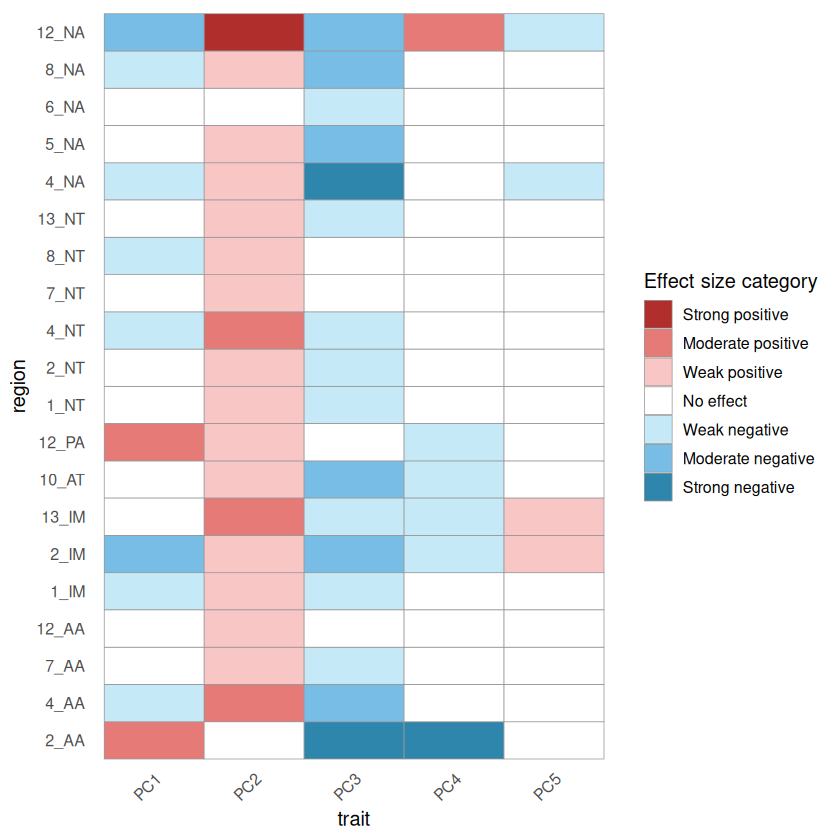

In [55]:
library(ggplot2)

df_plot <- df_long %>%
  mutate(effect_size_category = case_when(
    effect_size == "negligible"                  ~  0,
    effect_size == "small"  & cliffs_delta > 0  ~  1,
    effect_size == "medium" & cliffs_delta > 0  ~  2,
    effect_size == "large"  & cliffs_delta > 0  ~  3,
    effect_size == "small"  & cliffs_delta < 0  ~ -1,
    effect_size == "medium" & cliffs_delta < 0  ~ -2,
    effect_size == "large"  & cliffs_delta < 0  ~ -3,
    TRUE ~ NA_real_
  )) %>%
  mutate(trait = factor(trait, levels = paste0("PC", 1:5))) %>%
  mutate(region_order = factor(
    sub(".*_", "", region),
    levels = c("AA", "IM", "AT", "PA", "NT", "NA")
  )) %>%
  mutate(region = factor(region, levels = unique(region[order(region_order)])))

p <- ggplot(df_plot, aes(
    x = trait,
    y = region,
    fill = factor(effect_size_category, levels = rev(c(-3, -2, -1, 0, 1, 2, 3)))
  )) +
  geom_tile(color = "grey60") +
  scale_fill_manual(
    name = "Effect size category",
    values = c(
      "-3" = "#2F86AC",
      "-2" = "#77bde6",
      "-1" = "#c6e9f7",
      "0"  = "white",
      "1"  = "#f7c6c5",
      "2"  = "#e67a77",
      "3"  = "#b02f2c"
    ),
    labels = c(
      "-3" = "Strong negative",
      "-2" = "Moderate negative",
      "-1" = "Weak negative",
      "0"  = "No effect",
      "1"  = "Weak positive",
      "2"  = "Moderate positive",
      "3"  = "Strong positive"
    )
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),  # 45° looks cleaner for PC1-5
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank()
  )

ggsave("~/Func_Neo_Phytes/Results/Figures/PC_effect_heatmap.png",
       plot = p, width = 8, height = 6, dpi = 300)
print(p)

## add trait uncertainty

In [56]:
combined_data <- read.csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10_notrim_misstree.csv")

In [57]:
head(combined_data)

,h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,⋯,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47,region
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,83001afffffffff,all,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152,11_PA
2,83001afffffffff,native,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152,11_PA
3,83001cfffffffff,all,-10.005360,-0.2380058,0.2491376,2.9137390,0.9757523,1,1,16.22,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3166111,0.175,
4,83001cfffffffff,native,-9.988809,-0.3014320,0.2822225,2.9136399,0.9666302,1,1,16.22,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3291221,0.175,
5,83001efffffffff,all,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211,11_PA
6,83001efffffffff,native,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211,11_PA


In [58]:
# for each region, calculate mean perc_mean_na
mean_perc_mean_na <- aggregate(mean_perc_na ~ region, data = combined_data, FUN = mean)
mean_perc_mean_na

region,mean_perc_na
<chr>,<dbl>
,18.515643
1_AA,24.361367
1_AT,22.969979
1_IM,20.568345
1_NT,23.676128
1_OC,18.117500
1_PA,18.916548
10_AA,18.245625
10_AT,19.602535


In [59]:
# merge combined_results_region with mean_perc_mean_na
df_long_filtered <- merge(df_long_filtered, mean_perc_mean_na, by = "region", all.x = TRUE)

In [60]:
df_long_filtered

region,trait,cliffs_delta,effect_size,significance,mean_perc_na
<chr>,<chr>,<dbl>,<chr>,<chr>,<dbl>
1_IM,PC1,-0.2186413,small,***,20.568345
1_IM,PC2,0.1280893,small,**,20.568345
1_IM,PC3,-0.2492331,small,***,20.568345
1_NT,PC2,0.1233318,small,**,23.676128
1_NT,PC3,-0.1320601,small,***,23.676128
10_AT,PC2,0.2785162,small,*,19.602535
10_AT,PC3,-0.3594525,medium,**,19.602535
10_AT,PC4,-0.1650466,small,,19.602535
12_AA,PC2,0.2550749,small,*,26.741546


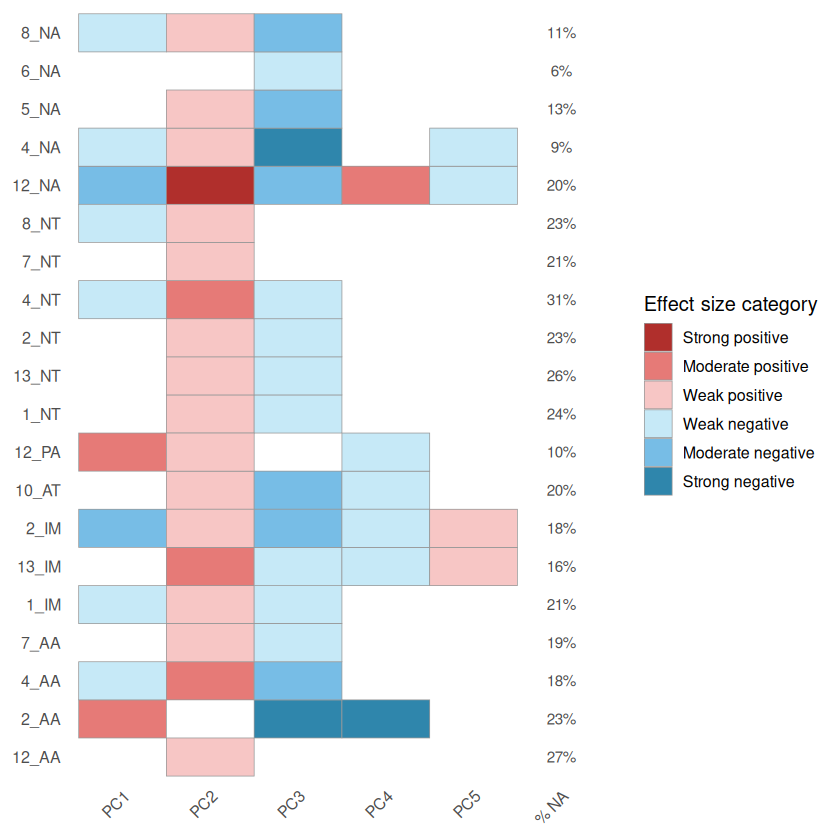

In [61]:
library(dplyr)
library(ggplot2)

df_plot <- df_long_filtered %>%
  mutate(effect_size_category = case_when(
    effect_size == "negligible"                 ~  0,
    effect_size == "small"  & cliffs_delta > 0  ~  1,
    effect_size == "medium" & cliffs_delta > 0  ~  2,
    effect_size == "large"  & cliffs_delta > 0  ~  3,
    effect_size == "small"  & cliffs_delta < 0  ~ -1,
    effect_size == "medium" & cliffs_delta < 0  ~ -2,
    effect_size == "large"  & cliffs_delta < 0  ~ -3,
    TRUE ~ NA_real_
  )) %>%
  mutate(trait = factor(trait, levels = paste0("PC", 1:5))) %>%
  mutate(region_order = factor(
    sub(".*_", "", region),
    levels = c("AA", "IM", "AT", "PA", "NT", "NA")
  )) %>%
  mutate(region = factor(region, levels = unique(region[order(region_order)])))

na_labels <- df_plot %>%
  distinct(region, mean_perc_na) %>%
  mutate(label = ifelse(is.na(mean_perc_na), "–", sprintf("%.0f%%", mean_perc_na)))

p <- ggplot(df_plot, aes(
    x = trait,
    y = region,
    fill = factor(effect_size_category, levels = rev(c(-3, -2, -1, 0, 1, 2, 3)))
  )) +
  geom_tile(color = "grey60") +
  geom_text(
    data = na_labels,
    aes(x = "% NA", y = region, label = label),
    inherit.aes = FALSE, size = 3.2, colour = "grey30"
  ) +
  scale_x_discrete(limits = c(paste0("PC", 1:5), "% NA")) +
  scale_fill_manual(
    name = "Effect size category",
    values = c(
      "-3" = "#2F86AC",
      "-2" = "#77bde6",
      "-1" = "#c6e9f7",
      "0"  = "white",
      "1"  = "#f7c6c5",
      "2"  = "#e67a77",
      "3"  = "#b02f2c"
    ),
    labels = c(
      "-3" = "Strong negative",
      "-2" = "Moderate negative",
      "-1" = "Weak negative",
      "0"  = "No effect",
      "1"  = "Weak positive",
      "2"  = "Moderate positive",
      "3"  = "Strong positive"
    )
  ) +
  labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank()
  )

ggsave("~/Func_Neo_Phytes/Results/Figures/PC_effect_heatmap_with_NA.png",
       plot = p, width = 8, height = 6, dpi = 300)
print(p)

#